In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT_DIR = Path.cwd()
if not (ROOT_DIR / "generalization_bounds.py").exists() and (ROOT_DIR / "Code").exists():
    ROOT_DIR = ROOT_DIR / "Code"
sys.path.insert(0, str(ROOT_DIR))

from generalization_bounds import (
    ConditionalOutputExperimentConfig,
    bounded_loss_cmi_bound,
    GaussianMixtureReference,
    collect_package_versions,
    conditional_supersample_norm_prefactor,
    estimate_empirical_generalization,
    estimate_mutual_information,
    estimate_samplewise_loss_proxy_mi,
    estimate_supersample_proxy_norms,
    estimate_theorem1_sensitivity_proxy,
    estimate_v_alpha_from_marginal,
    generate_regression_dataset,
    generate_supersample,
    make_holdout_set,
    make_w_true,
    posterior_from_dataset,
    prior_gaussian_reference,
    save_json,
    select_dataset_from_supersample,
    sigma_loss_sq,
    corollary1_subgaussian_multiplier,
    subgaussian_multiplier,
)

OUTPUT_DIR = ROOT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
from paper_figures import plot_conditional_output_paper_figures
from paper_figure_style import save_paper_figure


In [2]:
# Shared Bayesian linear regression and supersample budgets
sigma_noise_sq = 0.16
lambda_prior = 2.0
clip_c = 4.0
w_true_value = 0.8
dimensions = [1, 2, 5, 10]
alpha_values = [round(1.05 + 0.05 * i, 2) for i in range(40)]
n = 100

num_datasets = 256
num_reference_datasets = 256
num_holdout = 10_000

# Conditional supersample budgets
num_supersamples = 20
num_u_samples = 24
num_marginal_components = 32
num_weight_samples = 384
num_mi_weight_samples = 6

# Conditional proxy candidate budget.
# This controls the max-over-w candidate set for the conditional proxy prefactor.
proxy_num_means = 32
proxy_num_marginal_samples = 64

# Sample-wise proxy baseline
samplewise_num_weight_samples = 2
samplewise_num_bins = 12

# Optional output-space estimator settings.
output_test_size_max = 4
output_num_weight_samples = 384

seed = 20260419

config = ConditionalOutputExperimentConfig(
    sigma_noise_sq=sigma_noise_sq,
    lambda_prior=lambda_prior,
    clip_c=clip_c,
    w_true_value=w_true_value,
    dimensions=tuple(dimensions),
    alpha_values=tuple(alpha_values),
    n=n,
    num_datasets=num_datasets,
    num_reference_datasets=num_reference_datasets,
    num_holdout=num_holdout,
    num_supersamples=num_supersamples,
    num_u_samples=num_u_samples,
    num_marginal_components=num_marginal_components,
    num_weight_samples=num_weight_samples,
    num_mi_weight_samples=num_mi_weight_samples,
    proxy_num_means=proxy_num_means,
    proxy_num_marginal_samples=proxy_num_marginal_samples,
    samplewise_num_weight_samples=samplewise_num_weight_samples,
    samplewise_num_bins=samplewise_num_bins,
    output_test_size_max=output_test_size_max,
    output_num_weight_samples=output_num_weight_samples,
    seed=seed,
    artifact_prefix="blr_conditional_split",
    output_dir=str(OUTPUT_DIR),
)

# Select alpha and evaluate bounds on independent pools.
parameter_profile_selection_repeats = 4
parameter_profile_evaluation_repeats = 4

# MI has no alpha selection, so these are just independent MC repeats.
parameter_mi_repeats = 4
parameter_mi_weight_samples = num_mi_weight_samples

# Theorem-1 finite-candidate proxy split-selection repeats.
theorem1_proxy_selection_repeats = 4
theorem1_proxy_evaluation_repeats = 4

# Candidate budget for the unconditional Theorem-1 proxy curve.
theorem1_proxy_num_means = 64
theorem1_proxy_num_marginal_samples = 128
theorem1_proxy_num_prior_samples = 32
theorem1_candidate_batch_size = 256

print("Config:")
print(json.dumps({**config.__dict__, "output_dir": Path(config.output_dir).name}, indent=2))

print("\nExtra split-selection / proxy budgets:")
print(json.dumps(
    {
        "parameter_profile_selection_repeats": parameter_profile_selection_repeats,
        "parameter_profile_evaluation_repeats": parameter_profile_evaluation_repeats,
        "parameter_mi_repeats": parameter_mi_repeats,
        "theorem1_proxy_selection_repeats": theorem1_proxy_selection_repeats,
        "theorem1_proxy_evaluation_repeats": theorem1_proxy_evaluation_repeats,
        "theorem1_proxy_posterior_means": theorem1_proxy_num_means,
        "theorem1_proxy_marginal_samples": theorem1_proxy_num_marginal_samples,
        "theorem1_proxy_prior_samples": theorem1_proxy_num_prior_samples,
        "theorem1_proxy_anchors": 2,
        "theorem1_proxy_total_requested_candidates": (
            theorem1_proxy_num_means
            + theorem1_proxy_num_marginal_samples
            + theorem1_proxy_num_prior_samples
            + 2
        ),
    },
    indent=2,
))

print("\nPackage versions:")
print(json.dumps(collect_package_versions(), indent=2))

Config:
{
  "sigma_noise_sq": 0.16,
  "lambda_prior": 2.0,
  "clip_c": 4.0,
  "w_true_value": 0.8,
  "dimensions": [
    1,
    2,
    5,
    10
  ],
  "alpha_values": [
    1.05,
    1.1,
    1.15,
    1.2,
    1.25,
    1.3,
    1.35,
    1.4,
    1.45,
    1.5,
    1.55,
    1.6,
    1.65,
    1.7,
    1.75,
    1.8,
    1.85,
    1.9,
    1.95,
    2.0,
    2.05,
    2.1,
    2.15,
    2.2,
    2.25,
    2.3,
    2.35,
    2.4,
    2.45,
    2.5,
    2.55,
    2.6,
    2.65,
    2.7,
    2.75,
    2.8,
    2.85,
    2.9,
    2.95,
    3.0
  ],
  "n": 100,
  "num_datasets": 256,
  "num_reference_datasets": 256,
  "num_holdout": 10000,
  "num_supersamples": 20,
  "num_u_samples": 24,
  "num_marginal_components": 32,
  "num_weight_samples": 384,
  "num_mi_weight_samples": 6,
  "proxy_num_means": 32,
  "proxy_num_marginal_samples": 64,
  "samplewise_num_weight_samples": 2,
  "samplewise_num_bins": 12,
  "output_test_size_max": 4,
  "output_num_weight_samples": 384,
  "seed": 20260419,


In [3]:
def standard_error(values) -> float:
    values = np.asarray(values, dtype=float)
    if values.size <= 1:
        return 0.0
    return float(np.std(values, ddof=1) / np.sqrt(values.size))


def sqrt_bound_from_information(
    information_value: float,
    sigma_loss_sq_value: float,
    n: int,
) -> float:
    information_value = max(float(information_value), 0.0)
    return float(np.sqrt(2.0 * sigma_loss_sq_value / n * information_value))


def sqrt_bound_stderr_from_information_samples(
    information_samples,
    sigma_loss_sq_value: float,
    n: int,
) -> float:
    """Delta-method standard error for sqrt(a * I_hat)."""
    samples = np.asarray(information_samples, dtype=float)
    samples = np.maximum(samples, 0.0)
    if samples.size <= 1:
        return 0.0

    mean_info = float(np.mean(samples))
    info_stderr = standard_error(samples)
    if mean_info <= 0.0:
        return 0.0

    a = 2.0 * sigma_loss_sq_value / n
    derivative = 0.5 * np.sqrt(a) / np.sqrt(mean_info)
    return float(abs(derivative) * info_stderr)


def mean_dict(dicts, alpha_values):
    return {
        float(alpha): float(np.mean([d[float(alpha)] for d in dicts]))
        for alpha in alpha_values
    }


def stderr_at_alpha(dicts, alpha):
    return standard_error([d[float(alpha)] for d in dicts])


def split_selected_value(
    *,
    selection_bound_dicts,
    evaluation_bound_dicts,
    alpha_values,
):
    """Select alpha on selection pool and evaluate on independent evaluation pool."""
    mean_selection = mean_dict(selection_bound_dicts, alpha_values)
    mean_evaluation = mean_dict(evaluation_bound_dicts, alpha_values)

    selected_alpha = min(mean_selection, key=mean_selection.get)

    return {
        "selected_alpha": float(selected_alpha),
        "selected_value": float(mean_evaluation[selected_alpha]),
        "selected_stderr": stderr_at_alpha(evaluation_bound_dicts, selected_alpha),
        "mean_selection_by_alpha": mean_selection,
        "mean_evaluation_by_alpha": mean_evaluation,
    }


def alpha_sample_dicts_from_lists(bound_lists_by_alpha, alpha_values):
    """Convert {alpha: [sample_0, ...]} into [{alpha: sample_i, ...}, ...]."""
    first_alpha = float(alpha_values[0])
    num_samples = len(bound_lists_by_alpha[first_alpha])
    return [
        {
            float(alpha): float(bound_lists_by_alpha[float(alpha)][sample_index])
            for alpha in alpha_values
        }
        for sample_index in range(num_samples)
    ]


def build_theorem1_candidate_weights(
    *,
    evaluation_posteriors,
    reference_mixture,
    prior_reference,
    w_true,
    rng,
    num_means,
    num_marginal_samples,
    num_prior_samples,
):
    """Build finite candidates for the Theorem-1 sensitivity proxy.

    This is a diagnostic candidate set, not a certified global supremum.
    """
    candidate_blocks = []
    source_blocks = []

    num_means = min(int(num_means), len(evaluation_posteriors))
    if num_means > 0:
        means = np.vstack([posterior.mean for posterior in evaluation_posteriors[:num_means]])
        candidate_blocks.append(means)
        source_blocks.append(np.full(means.shape[0], "posterior_mean", dtype=object))

    if num_marginal_samples > 0:
        marginal_samples = reference_mixture.sample(rng, int(num_marginal_samples))
        candidate_blocks.append(marginal_samples)
        source_blocks.append(np.full(marginal_samples.shape[0], "marginal_sample", dtype=object))

    if num_prior_samples > 0:
        prior_samples = prior_reference.sample(rng, int(num_prior_samples))
        candidate_blocks.append(prior_samples)
        source_blocks.append(np.full(prior_samples.shape[0], "prior_sample", dtype=object))

    anchors = np.vstack(
        [
            np.asarray(w_true, dtype=float).reshape(1, -1),
            np.zeros((1, w_true.shape[0]), dtype=float),
        ]
    )
    candidate_blocks.append(anchors)
    source_blocks.append(np.array(["w_true", "zero"], dtype=object))

    return np.vstack(candidate_blocks), np.concatenate(source_blocks)


def plot_curve_with_band(
    ax,
    x,
    y,
    yerr,
    *,
    fmt,
    label,
    linewidth=2,
    capsize=3,
    alpha_band=0.14,
):
    """Plot a discrete curve with error bars and a light uncertainty band."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    yerr = np.asarray(yerr, dtype=float)

    line = ax.errorbar(
        x,
        y,
        yerr=yerr,
        fmt=fmt,
        linewidth=linewidth,
        capsize=capsize,
        label=label,
    )
    color = line.lines[0].get_color()
    ax.fill_between(
        x,
        np.maximum(y - yerr, 0.0),
        y + yerr,
        color=color,
        alpha=alpha_band,
        linewidth=0,
    )
    return line

def portable_artifact_paths(paths):
    """Display artifact paths without a private machine directory."""
    return {
        key: str(Path("outputs") / Path(value).name)
        if key.endswith("_path") and isinstance(value, str) else value
        for key, value in paths.items()
    }


In [4]:
def run_conditional_output_extended_first_figure(
    config: ConditionalOutputExperimentConfig,
    *,
    parameter_profile_selection_repeats: int = 4,
    parameter_profile_evaluation_repeats: int = 4,
    parameter_mi_repeats: int = 4,
    parameter_mi_weight_samples: int = 6,
    theorem1_proxy_selection_repeats: int = 4,
    theorem1_proxy_evaluation_repeats: int = 4,
    theorem1_proxy_num_means: int = 64,
    theorem1_proxy_num_marginal_samples: int = 128,
    theorem1_proxy_num_prior_samples: int = 32,
    theorem1_candidate_batch_size: int = 256,
):
    """Run the conditional figure and add MI plus parameter-space curves.

    Alpha selection and uncertainty:
      - select alpha on independent selection pool
      - evaluate selected alpha on independent evaluation pool
      - compute uncertainty only from evaluation pool

    This applies to:
      - rigorous conditional V_alpha
      - proxy conditional V_alpha
      - rigorous parameter-space V_alpha / Corollary 2
      - proxy parameter-space V_alpha / Theorem 1
    """
    rng = np.random.default_rng(config.seed)
    output_dir = Path(config.output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    artifact_prefix = config.artifact_prefix
    sigma_loss_sq_value = sigma_loss_sq(config.clip_c)

    summary_records = []
    alpha_records = []
    theorem1_proxy_records = []
    sanity_records = []

    conditional_selection_cut = config.num_supersamples // 2
    conditional_evaluation_count = config.num_supersamples - conditional_selection_cut
    if conditional_selection_cut <= 0 or conditional_evaluation_count <= 0:
        raise ValueError("num_supersamples must be at least 2 for split-selection.")

    for dim in config.dimensions:
        print(f"Running dimension d={dim}...")
        w_true = make_w_true(dim, config.w_true_value)

        holdout = make_holdout_set(
            rng=rng,
            num_holdout=config.num_holdout,
            w_true=w_true,
            sigma_noise_sq=config.sigma_noise_sq,
        )

        evaluation_datasets = [
            generate_regression_dataset(
                rng=rng,
                n=config.n,
                w_true=w_true,
                sigma_noise_sq=config.sigma_noise_sq,
            )
            for _ in range(config.num_datasets)
        ]
        evaluation_posteriors = [
            posterior_from_dataset(
                x,
                y,
                lambda_prior=config.lambda_prior,
                sigma_noise_sq=config.sigma_noise_sq,
            )
            for x, y in evaluation_datasets
        ]

        empirical_gen, empirical_stderr = estimate_empirical_generalization(
            datasets=evaluation_datasets,
            posteriors=evaluation_posteriors,
            holdout=holdout,
            clip_c=config.clip_c,
            rng=rng,
        )

        # Conditional quantities with independent alpha selection/evaluation pools.
        cmi_estimates = []
        samplewise_bounds = []
        samplewise_mean_infos = []

        conditional_v_alpha_selection = {float(alpha): [] for alpha in config.alpha_values}
        conditional_v_alpha_evaluation = {float(alpha): [] for alpha in config.alpha_values}

        conditional_rigorous_selection = {float(alpha): [] for alpha in config.alpha_values}
        conditional_rigorous_evaluation = {float(alpha): [] for alpha in config.alpha_values}

        conditional_proxy_selection = {float(alpha): [] for alpha in config.alpha_values}
        conditional_proxy_evaluation = {float(alpha): [] for alpha in config.alpha_values}

        for supersample_index in range(config.num_supersamples):
            use_selection_pool = supersample_index < conditional_selection_cut

            supersample_x, supersample_y = generate_supersample(
                rng=rng,
                n=config.n,
                w_true=w_true,
                sigma_noise_sq=config.sigma_noise_sq,
            )

            reference_u_vectors = [
                rng.integers(0, 2, size=config.n)
                for _ in range(config.num_marginal_components)
            ]
            reference_posteriors = [
                posterior_from_dataset(
                    *select_dataset_from_supersample(supersample_x, supersample_y, u_vector),
                    lambda_prior=config.lambda_prior,
                    sigma_noise_sq=config.sigma_noise_sq,
                )
                for u_vector in reference_u_vectors
            ]
            conditional_reference_mixture = GaussianMixtureReference(reference_posteriors)

            evaluation_u_vectors = [
                rng.integers(0, 2, size=config.n)
                for _ in range(config.num_u_samples)
            ]
            evaluation_supersample_posteriors = [
                posterior_from_dataset(
                    *select_dataset_from_supersample(supersample_x, supersample_y, u_vector),
                    lambda_prior=config.lambda_prior,
                    sigma_noise_sq=config.sigma_noise_sq,
                )
                for u_vector in evaluation_u_vectors
            ]

            cmi_value, _ = estimate_mutual_information(
                posteriors=evaluation_supersample_posteriors,
                reference_mixture=conditional_reference_mixture,
                rng=rng,
                num_weight_samples=config.num_mi_weight_samples,
            )
            cmi_estimates.append(max(cmi_value, 0.0))

            v_alpha_values, _ = estimate_v_alpha_from_marginal(
                posteriors=evaluation_supersample_posteriors,
                reference_mixture=conditional_reference_mixture,
                alpha_values=config.alpha_values,
                rng=rng,
                num_weight_samples=config.num_weight_samples,
            )

            num_conditional_means = min(config.proxy_num_means, len(reference_posteriors))
            candidate_means = (
                np.vstack([posterior.mean for posterior in reference_posteriors[:num_conditional_means]])
                if num_conditional_means > 0
                else np.empty((0, dim), dtype=float)
            )
            candidate_samples = conditional_reference_mixture.sample(
                rng,
                config.proxy_num_marginal_samples,
            )
            candidate_weights = np.vstack([candidate_means, candidate_samples])

            proxy_norms = estimate_supersample_proxy_norms(
                supersample_x=supersample_x,
                supersample_y=supersample_y,
                candidate_weights=candidate_weights,
                evaluation_u_vectors=evaluation_u_vectors,
                alpha_values=config.alpha_values,
                clip_c=config.clip_c,
            )

            for alpha in config.alpha_values:
                alpha_float = float(alpha)
                v_value = float(v_alpha_values[alpha_float])
                rigorous_prefactor = conditional_supersample_norm_prefactor(
                    alpha_float,
                    config.n,
                    config.clip_c,
                )
                rigorous_bound = rigorous_prefactor * v_value
                proxy_bound = float(proxy_norms[alpha_float] * v_value)

                if use_selection_pool:
                    conditional_v_alpha_selection[alpha_float].append(v_value)
                    conditional_rigorous_selection[alpha_float].append(float(rigorous_bound))
                    conditional_proxy_selection[alpha_float].append(float(proxy_bound))
                else:
                    conditional_v_alpha_evaluation[alpha_float].append(v_value)
                    conditional_rigorous_evaluation[alpha_float].append(float(rigorous_bound))
                    conditional_proxy_evaluation[alpha_float].append(float(proxy_bound))

            samplewise_bound, samplewise_diag = estimate_samplewise_loss_proxy_mi(
                supersample_x=supersample_x,
                supersample_y=supersample_y,
                evaluation_u_vectors=evaluation_u_vectors,
                evaluation_posteriors=evaluation_supersample_posteriors,
                clip_c=config.clip_c,
                rng=rng,
                num_weight_samples=config.samplewise_num_weight_samples,
                num_bins=config.samplewise_num_bins,
            )
            samplewise_bounds.append(samplewise_bound)
            samplewise_mean_infos.append(samplewise_diag["mean_samplewise_mi"])

        conditional_rigorous_selection_dicts = alpha_sample_dicts_from_lists(
            conditional_rigorous_selection,
            config.alpha_values,
        )
        conditional_rigorous_evaluation_dicts = alpha_sample_dicts_from_lists(
            conditional_rigorous_evaluation,
            config.alpha_values,
        )
        conditional_proxy_selection_dicts = alpha_sample_dicts_from_lists(
            conditional_proxy_selection,
            config.alpha_values,
        )
        conditional_proxy_evaluation_dicts = alpha_sample_dicts_from_lists(
            conditional_proxy_evaluation,
            config.alpha_values,
        )

        rigorous_conditional_split = split_selected_value(
            selection_bound_dicts=conditional_rigorous_selection_dicts,
            evaluation_bound_dicts=conditional_rigorous_evaluation_dicts,
            alpha_values=config.alpha_values,
        )
        proxy_conditional_split = split_selected_value(
            selection_bound_dicts=conditional_proxy_selection_dicts,
            evaluation_bound_dicts=conditional_proxy_evaluation_dicts,
            alpha_values=config.alpha_values,
        )

        rigorous_conditional_selected_alpha = rigorous_conditional_split["selected_alpha"]
        rigorous_conditional_bound = rigorous_conditional_split["selected_value"]
        rigorous_conditional_stderr = rigorous_conditional_split["selected_stderr"]

        proxy_conditional_selected_alpha = proxy_conditional_split["selected_alpha"]
        proxy_conditional_bound = proxy_conditional_split["selected_value"]
        proxy_conditional_stderr = proxy_conditional_split["selected_stderr"]

        fixed_rigorous_conditional_v2_bound = float(
            np.mean(conditional_rigorous_evaluation[2.0])
        )
        fixed_rigorous_conditional_v2_stderr = standard_error(
            conditional_rigorous_evaluation[2.0]
        )

        fixed_proxy_conditional_v2_bound = float(
            np.mean(conditional_proxy_evaluation[2.0])
        )
        fixed_proxy_conditional_v2_stderr = standard_error(
            conditional_proxy_evaluation[2.0]
        )

        cmi_estimate = float(np.mean(cmi_estimates))
        # CMI uses the supersample difference scale c**2, not c**2/4.
        # Apply the same prefactor to the delta-method standard error.
        cmi_bound = bounded_loss_cmi_bound(cmi_estimate, config.clip_c, config.n)
        cmi_bound_stderr = sqrt_bound_stderr_from_information_samples(
            cmi_estimates,
            config.clip_c ** 2,
            config.n,
        )

        samplewise_bound_mean = float(np.mean(samplewise_bounds))
        samplewise_bound_stderr = standard_error(samplewise_bounds)

        # Parameter-space reference mixture for added unconditional curves.
        reference_datasets = [
            generate_regression_dataset(
                rng=rng,
                n=config.n,
                w_true=w_true,
                sigma_noise_sq=config.sigma_noise_sq,
            )
            for _ in range(config.num_reference_datasets)
        ]
        reference_posteriors = [
            posterior_from_dataset(
                x,
                y,
                lambda_prior=config.lambda_prior,
                sigma_noise_sq=config.sigma_noise_sq,
            )
            for x, y in reference_datasets
        ]
        parameter_reference_mixture = GaussianMixtureReference(reference_posteriors)

        # Parameter-space MI bound.
        # MI is not alpha-dependent, so it only needs repeated MC estimates.
        parameter_mi_samples = []
        parameter_mi_bounds = []
        for repeat_index in range(parameter_mi_repeats):
            mi_value, _ = estimate_mutual_information(
                posteriors=evaluation_posteriors,
                reference_mixture=parameter_reference_mixture,
                rng=np.random.default_rng(
                    config.seed + 100_000 + int(dim) * 1_000 + repeat_index
                ),
                num_weight_samples=parameter_mi_weight_samples,
            )
            mi_value = max(float(mi_value), 0.0)
            parameter_mi_samples.append(mi_value)
            parameter_mi_bounds.append(
                sqrt_bound_from_information(
                    mi_value,
                    sigma_loss_sq_value,
                    config.n,
                )
            )

        parameter_mi_estimate = float(np.mean(parameter_mi_samples))
        parameter_mi_bound = float(np.mean(parameter_mi_bounds))
        parameter_mi_bound_stderr = standard_error(parameter_mi_bounds)

        # Rigorous parameter-space V_alpha / Corollary 2 with Option 1 split-selection.
        parameter_selection_bounds = []
        parameter_evaluation_bounds = []
        parameter_corollary1_selection_bounds = []
        parameter_corollary1_evaluation_bounds = []
        parameter_evaluation_v_alpha = []

        for repeat_index in range(parameter_profile_selection_repeats):
            v_alpha_values, _ = estimate_v_alpha_from_marginal(
                posteriors=evaluation_posteriors,
                reference_mixture=parameter_reference_mixture,
                alpha_values=config.alpha_values,
                rng=np.random.default_rng(
                    config.seed + 200_000 + int(dim) * 1_000 + repeat_index
                ),
                num_weight_samples=config.output_num_weight_samples,
            )

            parameter_selection_bounds.append(
                {
                    float(alpha): float(
                        subgaussian_multiplier(float(alpha), sigma_loss_sq_value, config.n)
                        * v_alpha_values[float(alpha)]
                    )
                    for alpha in config.alpha_values
                }
            )

            parameter_corollary1_selection_bounds.append(
                {
                    float(alpha): float(
                        corollary1_subgaussian_multiplier(float(alpha), sigma_loss_sq_value, config.n)
                        * v_alpha_values[float(alpha)]
                    )
                    for alpha in config.alpha_values
                }
            )

        for repeat_index in range(parameter_profile_evaluation_repeats):
            v_alpha_values, _ = estimate_v_alpha_from_marginal(
                posteriors=evaluation_posteriors,
                reference_mixture=parameter_reference_mixture,
                alpha_values=config.alpha_values,
                rng=np.random.default_rng(
                    config.seed + 210_000 + int(dim) * 1_000 + repeat_index
                ),
                num_weight_samples=config.output_num_weight_samples,
            )

            parameter_evaluation_v_alpha.append(v_alpha_values)
            parameter_evaluation_bounds.append(
                {
                    float(alpha): float(
                        subgaussian_multiplier(float(alpha), sigma_loss_sq_value, config.n)
                        * v_alpha_values[float(alpha)]
                    )
                    for alpha in config.alpha_values
                }
            )

            parameter_corollary1_evaluation_bounds.append(
                {
                    float(alpha): float(
                        corollary1_subgaussian_multiplier(float(alpha), sigma_loss_sq_value, config.n)
                        * v_alpha_values[float(alpha)]
                    )
                    for alpha in config.alpha_values
                }
            )

        parameter_split = split_selected_value(
            selection_bound_dicts=parameter_selection_bounds,
            evaluation_bound_dicts=parameter_evaluation_bounds,
            alpha_values=config.alpha_values,
        )
        parameter_corollary1_split = split_selected_value(
            selection_bound_dicts=parameter_corollary1_selection_bounds,
            evaluation_bound_dicts=parameter_corollary1_evaluation_bounds,
            alpha_values=config.alpha_values,
        )

        parameter_selected_alpha = parameter_split["selected_alpha"]
        parameter_rigorous_bound = parameter_split["selected_value"]
        parameter_rigorous_stderr = parameter_split["selected_stderr"]

        parameter_corollary1_selected_alpha = parameter_corollary1_split["selected_alpha"]
        parameter_corollary1_bound = parameter_corollary1_split["selected_value"]
        parameter_corollary1_stderr = parameter_corollary1_split["selected_stderr"]

        mean_parameter_selection_bounds = parameter_split["mean_selection_by_alpha"]
        mean_parameter_evaluation_bounds = parameter_split["mean_evaluation_by_alpha"]
        mean_parameter_corollary1_selection_bounds = parameter_corollary1_split["mean_selection_by_alpha"]
        mean_parameter_corollary1_evaluation_bounds = parameter_corollary1_split["mean_evaluation_by_alpha"]

        fixed_parameter_v2_bound = float(
            np.mean([repeat_bounds[2.0] for repeat_bounds in parameter_evaluation_bounds])
        )
        fixed_parameter_v2_stderr = standard_error(
            [repeat_bounds[2.0] for repeat_bounds in parameter_evaluation_bounds]
        )

        mean_parameter_v_alpha = mean_dict(parameter_evaluation_v_alpha, config.alpha_values)

        # Proxy V_alpha / Theorem 1 with Option 1 split-selection.
        prior_reference = prior_gaussian_reference(dim, config.lambda_prior)

        theorem1_selection_bounds = []
        theorem1_evaluation_bounds = []
        theorem1_evaluation_sensitivities = []
        theorem1_candidate_counts = []
        theorem1_source_count_records = []

        def compute_theorem1_proxy_repeat(repeat_rng):
            repeat_v_alpha, _ = estimate_v_alpha_from_marginal(
                posteriors=evaluation_posteriors,
                reference_mixture=parameter_reference_mixture,
                alpha_values=config.alpha_values,
                rng=repeat_rng,
                num_weight_samples=config.output_num_weight_samples,
            )

            candidates, candidate_sources = build_theorem1_candidate_weights(
                evaluation_posteriors=evaluation_posteriors,
                reference_mixture=parameter_reference_mixture,
                prior_reference=prior_reference,
                w_true=w_true,
                rng=repeat_rng,
                num_means=theorem1_proxy_num_means,
                num_marginal_samples=theorem1_proxy_num_marginal_samples,
                num_prior_samples=theorem1_proxy_num_prior_samples,
            )

            sensitivity_profile = estimate_theorem1_sensitivity_proxy(
                candidates=candidates,
                candidate_sources=candidate_sources,
                datasets=evaluation_datasets,
                holdout=holdout,
                alpha_values=config.alpha_values,
                clip_c=config.clip_c,
                batch_size=theorem1_candidate_batch_size,
            )

            bounds = {
                float(alpha): float(
                    sensitivity_profile["sensitivity_by_alpha"][float(alpha)]
                    * repeat_v_alpha[float(alpha)]
                )
                for alpha in config.alpha_values
            }

            sensitivities = {
                float(alpha): float(
                    sensitivity_profile["sensitivity_by_alpha"][float(alpha)]
                )
                for alpha in config.alpha_values
            }

            return bounds, sensitivities, float(candidates.shape[0]), sensitivity_profile["source_counts"]

        for repeat_index in range(theorem1_proxy_selection_repeats):
            repeat_rng = np.random.default_rng(
                config.seed + 300_000 + int(dim) * 1_000 + repeat_index
            )
            bounds, _, _, _ = compute_theorem1_proxy_repeat(repeat_rng)
            theorem1_selection_bounds.append(bounds)

        for repeat_index in range(theorem1_proxy_evaluation_repeats):
            repeat_rng = np.random.default_rng(
                config.seed + 310_000 + int(dim) * 1_000 + repeat_index
            )
            bounds, sensitivities, candidate_count, source_counts = compute_theorem1_proxy_repeat(
                repeat_rng
            )
            theorem1_evaluation_bounds.append(bounds)
            theorem1_evaluation_sensitivities.append(sensitivities)
            theorem1_candidate_counts.append(candidate_count)
            theorem1_source_count_records.append(source_counts)

        theorem1_split = split_selected_value(
            selection_bound_dicts=theorem1_selection_bounds,
            evaluation_bound_dicts=theorem1_evaluation_bounds,
            alpha_values=config.alpha_values,
        )

        theorem1_selected_alpha = theorem1_split["selected_alpha"]
        theorem1_proxy_bound = theorem1_split["selected_value"]
        theorem1_proxy_stderr = theorem1_split["selected_stderr"]

        mean_theorem1_selection_bounds = theorem1_split["mean_selection_by_alpha"]
        mean_theorem1_evaluation_bounds = theorem1_split["mean_evaluation_by_alpha"]

        theorem1_proxy_records.append(
            {
                "dimension": float(dim),
                "candidate_count_mean": float(np.mean(theorem1_candidate_counts)),
                "candidate_count_stderr": standard_error(theorem1_candidate_counts),
                "candidate_sources_last_repeat_json": json.dumps(
                    theorem1_source_count_records[-1],
                    sort_keys=True,
                ),
                "selected_alpha": float(theorem1_selected_alpha),
                "selected_bound": theorem1_proxy_bound,
                "selected_bound_stderr": theorem1_proxy_stderr,
                "selected_sensitivity_mean": float(
                    np.mean([
                        repeat_sensitivity[theorem1_selected_alpha]
                        for repeat_sensitivity in theorem1_evaluation_sensitivities
                    ])
                ),
                "selected_sensitivity_stderr": standard_error(
                    [
                        repeat_sensitivity[theorem1_selected_alpha]
                        for repeat_sensitivity in theorem1_evaluation_sensitivities
                    ]
                ),
            }
        )

        # Summary table.
        summary_records.append(
            {
                "dimension": float(dim),

                "empirical_generalization": float(empirical_gen),
                "empirical_generalization_stderr": float(empirical_stderr),

                "mi_estimate": parameter_mi_estimate,
                "mi_bound": parameter_mi_bound,
                "mi_bound_stderr": parameter_mi_bound_stderr,

                "cmi_estimate": cmi_estimate,
                "cmi_bound": cmi_bound,
                "cmi_bound_stderr": cmi_bound_stderr,

                "samplewise_loss_proxy_bound": samplewise_bound_mean,
                "samplewise_loss_proxy_bound_stderr": samplewise_bound_stderr,

                "rigorous_conditional_v_alpha_bound": rigorous_conditional_bound,
                "rigorous_conditional_v_alpha_bound_stderr": rigorous_conditional_stderr,
                "rigorous_conditional_selected_alpha": float(rigorous_conditional_selected_alpha),

                "proxy_conditional_v_alpha_bound": proxy_conditional_bound,
                "proxy_conditional_v_alpha_bound_stderr": proxy_conditional_stderr,
                "proxy_conditional_selected_alpha": float(proxy_conditional_selected_alpha),

                "fixed_rigorous_conditional_v2_bound": fixed_rigorous_conditional_v2_bound,
                "fixed_rigorous_conditional_v2_bound_stderr": fixed_rigorous_conditional_v2_stderr,

                "fixed_proxy_conditional_v2_bound": fixed_proxy_conditional_v2_bound,
                "fixed_proxy_conditional_v2_bound_stderr": fixed_proxy_conditional_v2_stderr,

                "rigorous_parameter_v_alpha_bound": parameter_rigorous_bound,
                "rigorous_parameter_v_alpha_bound_stderr": parameter_rigorous_stderr,
                "rigorous_parameter_selected_alpha": float(parameter_selected_alpha),

                "corollary1_parameter_v_alpha_bound": parameter_corollary1_bound,
                "corollary1_parameter_v_alpha_bound_stderr": parameter_corollary1_stderr,
                "corollary1_parameter_selected_alpha": float(parameter_corollary1_selected_alpha),

                "proxy_theorem1_v_alpha_bound": theorem1_proxy_bound,
                "proxy_theorem1_v_alpha_bound_stderr": theorem1_proxy_stderr,
                "proxy_theorem1_selected_alpha": float(theorem1_selected_alpha),

                "fixed_parameter_v2_bound": fixed_parameter_v2_bound,
                "fixed_parameter_v2_bound_stderr": fixed_parameter_v2_stderr,

                "theorem1_proxy_candidate_count_mean": float(np.mean(theorem1_candidate_counts)),
            }
        )

        sanity_records.append(
            {
                "dimension": float(dim),
                "mi_nonnegative": bool(parameter_mi_estimate >= -1e-9),
                "cmi_nonnegative": bool(cmi_estimate >= -1e-9),
                "samplewise_nonnegative": bool(samplewise_bound_mean >= -1e-9),

                "conditional_selection_supersamples": float(conditional_selection_cut),
                "conditional_evaluation_supersamples": float(conditional_evaluation_count),
                "conditional_proxy_candidate_count": float(
                    min(config.proxy_num_means, config.num_marginal_components)
                    + config.proxy_num_marginal_samples
                ),

                "parameter_profile_selection_repeats": float(parameter_profile_selection_repeats),
                "parameter_profile_evaluation_repeats": float(parameter_profile_evaluation_repeats),
                "parameter_mi_repeats": float(parameter_mi_repeats),

                "theorem1_proxy_selection_repeats": float(theorem1_proxy_selection_repeats),
                "theorem1_proxy_evaluation_repeats": float(theorem1_proxy_evaluation_repeats),
                "theorem1_proxy_candidate_count_mean": float(np.mean(theorem1_candidate_counts)),

                "mean_samplewise_mi": float(np.mean(samplewise_mean_infos)),
            }
        )

        # Per-alpha profile table.
        mean_conditional_rigorous_selection = rigorous_conditional_split["mean_selection_by_alpha"]
        mean_conditional_rigorous_evaluation = rigorous_conditional_split["mean_evaluation_by_alpha"]
        mean_conditional_proxy_selection = proxy_conditional_split["mean_selection_by_alpha"]
        mean_conditional_proxy_evaluation = proxy_conditional_split["mean_evaluation_by_alpha"]

        for alpha in config.alpha_values:
            alpha_float = float(alpha)

            alpha_records.append(
                {
                    "dimension": float(dim),
                    "alpha": alpha_float,

                    "conditional_v_alpha_selection": float(
                        np.mean(conditional_v_alpha_selection[alpha_float])
                    ),
                    "conditional_v_alpha_evaluation": float(
                        np.mean(conditional_v_alpha_evaluation[alpha_float])
                    ),
                    "conditional_v_alpha_evaluation_stderr": standard_error(
                        conditional_v_alpha_evaluation[alpha_float]
                    ),

                    "conditional_rigorous_bound_selection": float(
                        mean_conditional_rigorous_selection[alpha_float]
                    ),
                    "conditional_rigorous_bound_evaluation": float(
                        mean_conditional_rigorous_evaluation[alpha_float]
                    ),
                    "conditional_rigorous_bound_evaluation_stderr": standard_error(
                        conditional_rigorous_evaluation[alpha_float]
                    ),

                    "conditional_proxy_bound_selection": float(
                        mean_conditional_proxy_selection[alpha_float]
                    ),
                    "conditional_proxy_bound_evaluation": float(
                        mean_conditional_proxy_evaluation[alpha_float]
                    ),
                    "conditional_proxy_bound_evaluation_stderr": standard_error(
                        conditional_proxy_evaluation[alpha_float]
                    ),

                    "parameter_v_alpha_evaluation": float(mean_parameter_v_alpha[alpha_float]),
                    "parameter_corollary1_bound_selection": float(
                        mean_parameter_corollary1_selection_bounds[alpha_float]
                    ),
                    "parameter_corollary1_bound_evaluation": float(
                        mean_parameter_corollary1_evaluation_bounds[alpha_float]
                    ),
                    "parameter_corollary1_bound_evaluation_stderr": stderr_at_alpha(
                        parameter_corollary1_evaluation_bounds,
                        alpha_float,
                    ),

                    "theorem1_proxy_bound_selection": float(
                        mean_theorem1_selection_bounds[alpha_float]
                    ),
                    "theorem1_proxy_bound_evaluation": float(
                        mean_theorem1_evaluation_bounds[alpha_float]
                    ),
                    "theorem1_proxy_bound_evaluation_stderr": stderr_at_alpha(
                        theorem1_evaluation_bounds,
                        alpha_float,
                    ),
                    "theorem1_proxy_sensitivity_evaluation": float(
                        np.mean([
                            repeat_sensitivity[alpha_float]
                            for repeat_sensitivity in theorem1_evaluation_sensitivities
                        ])
                    ),
                    "theorem1_proxy_sensitivity_evaluation_stderr": standard_error(
                        [
                            repeat_sensitivity[alpha_float]
                            for repeat_sensitivity in theorem1_evaluation_sensitivities
                        ]
                    ),
                }
            )

    summary_frame = pd.DataFrame(summary_records)
    alpha_frame = pd.DataFrame(alpha_records)
    theorem1_proxy_frame = pd.DataFrame(theorem1_proxy_records)
    sanity_frame = pd.DataFrame(sanity_records)

    # Extended first figure with MI and Option 1 split-selection uncertainty bands.
    fig, fig_alpha = plot_conditional_output_paper_figures(summary_frame)

    figure_path = output_dir / f"{artifact_prefix}_conditional_bounds_extended.png"
    figure_pdf_path = output_dir / f"{artifact_prefix}_conditional_bounds_extended.pdf"
    figure_eps_path = output_dir / f"{artifact_prefix}_conditional_bounds_extended.eps"

    alpha_figure_path = output_dir / f"{artifact_prefix}_conditional_bounds_extended_alpha_selected.png"
    alpha_figure_pdf_path = output_dir / f"{artifact_prefix}_conditional_bounds_extended_alpha_selected.pdf"
    alpha_figure_eps_path = output_dir / f"{artifact_prefix}_conditional_bounds_extended_alpha_selected.eps"

    table_path = output_dir / f"{artifact_prefix}_conditional_bounds_extended.csv"
    alpha_path = output_dir / f"{artifact_prefix}_conditional_bounds_extended_alpha.csv"
    theorem1_proxy_path = output_dir / f"{artifact_prefix}_theorem1_proxy_summary.csv"
    sanity_path = output_dir / f"{artifact_prefix}_conditional_bounds_extended_sanity.csv"
    config_path = output_dir / f"{artifact_prefix}_conditional_bounds_extended_config.json"

    save_paper_figure(fig, figure_pdf_path.with_suffix(""), 4)
    plt.close(fig)

    save_paper_figure(fig_alpha, alpha_figure_pdf_path.with_suffix(""), 5)
    plt.close(fig_alpha)

    summary_frame.to_csv(table_path, index=False)
    alpha_frame.to_csv(alpha_path, index=False)
    theorem1_proxy_frame.to_csv(theorem1_proxy_path, index=False)
    sanity_frame.to_csv(sanity_path, index=False)

    save_json(
        {
            "config": {**config.__dict__, "output_dir": Path(config.output_dir).name},
            "paper_corollary_number": 2,
            "legacy_identifier_note": "corollary1_* identifiers refer to the current paper Corollary 2; names are retained for compatibility.",
            "package_versions": collect_package_versions(),
            "information_bound_formulas": {'information_units': 'nats (natural logarithms)', 'mi_bound': 'clip_c * sqrt(I(W;S) / (2*n))', 'cmi_bound': 'clip_c * sqrt(2 * I(W;U | supersample) / n)', 'cmi_loss_difference_subgaussian_proxy': 'clip_c**2'},
            "added_curves": {
                "mi_bound": "Parameter-space MI bound using corrected marginal mixture",
                "rigorous_parameter_v_alpha": "Corollary 2 / subgaussian, split-selected over alpha",
                "corollary1_parameter_v_alpha": "Pure Corollary 2 / subgaussian, split-selected over alpha",
                "proxy_theorem1_v_alpha": "Theorem 1 finite-candidate sensitivity proxy, split-selected over alpha",
                "fixed_parameter_v2": "Theorem 2 / variance bound at alpha=2",
            },
            "option_1_uncertainty_bands": {
                "description": (
                    "For alpha-dependent optimized bounds, alpha is selected on an independent "
                    "selection pool and evaluated on an independent evaluation pool. Error bands "
                    "are computed only on the evaluation pool at the selected alpha."
                ),
                "alpha_dependent_curves": [
                    "rigorous_conditional_v_alpha",
                    "proxy_conditional_v_alpha",
                    "rigorous_parameter_v_alpha",
                    "corollary1_parameter_v_alpha",
                    "proxy_theorem1_v_alpha",
                ],
            },
            "split_selection": {
                "conditional_selection_supersamples": conditional_selection_cut,
                "conditional_evaluation_supersamples": conditional_evaluation_count,
                "parameter_profile_selection_repeats": parameter_profile_selection_repeats,
                "parameter_profile_evaluation_repeats": parameter_profile_evaluation_repeats,
                "theorem1_proxy_selection_repeats": theorem1_proxy_selection_repeats,
                "theorem1_proxy_evaluation_repeats": theorem1_proxy_evaluation_repeats,
            },
            "uncertainty": {
                "empirical_generalization": "sample standard error across datasets",
                "mi": "standard error across repeated independent MI MC estimates",
                "cmi": "standard error across supersample CMI estimates with delta-method bound transform",
                "conditional_v_alpha": "standard error on independent evaluation supersamples at split-selected alpha",
                "rigorous_parameter_v_alpha": "standard error on independent evaluation repeats at split-selected alpha",
                "corollary1_parameter_v_alpha": "standard error on independent evaluation repeats at split-selected alpha",
                "proxy_theorem1_v_alpha": "standard error on independent evaluation proxy repeats at split-selected alpha",
                "fixed_v2": "standard error across evaluation V_alpha MC estimates at alpha=2",
            },
            "theorem1_proxy_candidate_budget": {
                "posterior_means": theorem1_proxy_num_means,
                "marginal_samples": theorem1_proxy_num_marginal_samples,
                "prior_samples": theorem1_proxy_num_prior_samples,
                "anchors": 2,
                "candidate_batch_size": theorem1_candidate_batch_size,
            },
            "warning": (
                "Theorem-1 proxy uses a finite candidate maximum and is not a theorem-valid "
                "global supremum unless externally certified."
            ),
        },
        config_path,
    )

    return {
        "conditional_results": summary_frame,
        "conditional_alpha": alpha_frame,
        "theorem1_proxy_summary": theorem1_proxy_frame,
        "sanity": sanity_frame,
        "diagnostics": {
            "figure_path": str(figure_path),
            "figure_pdf_path": str(figure_pdf_path),
            "alpha_figure_path": str(alpha_figure_path),
            "alpha_figure_pdf_path": str(alpha_figure_pdf_path),
            "table_path": str(table_path),
            "alpha_path": str(alpha_path),
            "theorem1_proxy_path": str(theorem1_proxy_path),
            "sanity_path": str(sanity_path),
            "config_path": str(config_path),
        },
        "package_versions": collect_package_versions(),
        "config": config.__dict__,
    }

Running dimension d=1...


Running dimension d=2...


Running dimension d=5...


Running dimension d=10...


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


...

,dimension,empirical_generalization,empirical_generalization_stderr,mi_estimate,mi_bound,mi_bound_stderr,cmi_estimate,cmi_bound,cmi_bound_stderr,samplewise_loss_proxy_bound,samplewise_loss_proxy_bound_stderr,rigorous_conditional_v_alpha_bound,rigorous_conditional_v_alpha_bound_stderr,rigorous_conditional_selected_alpha,proxy_conditional_v_alpha_bound,proxy_conditional_v_alpha_bound_stderr,proxy_conditional_selected_alpha,fixed_rigorous_conditional_v2_bound,fixed_rigorous_conditional_v2_bound_stderr,fixed_proxy_conditional_v2_bound,fixed_proxy_conditional_v2_bound_stderr,rigorous_parameter_v_alpha_bound,rigorous_parameter_v_alpha_bound_stderr,rigorous_parameter_selected_alpha,corollary1_parameter_v_alpha_bound,corollary1_parameter_v_alpha_bound_stderr,corollary1_parameter_selected_alpha,proxy_theorem1_v_alpha_bound,proxy_theorem1_v_alpha_bound_stderr,proxy_theorem1_selected_alpha,fixed_parameter_v2_bound,fixed_parameter_v2_bound_stderr,theorem1_proxy_candidate_count_mean
0,1.0,0.000593,0.001489,0.348529,0.166946,0.001958,0.211387,0.260084,0.014281,4.064979,0.028169,0.211245,0.018732,2.00,0.020442,0.002791,1.90,0.211245,0.018732,0.020407,0.002832,0.164665,0.004374,2.00,0.272532,0.004708,1.30,0.141471,0.003996,1.80,0.164665,0.004374,226.0
1,2.0,0.002232,0.001338,0.703462,0.237193,0.002348,0.459938,0.383641,0.008166,3.697100,0.031532,0.383507,0.017187,2.00,0.036399,0.003043,1.70,0.383507,0.017187,0.037035,0.003124,0.272668,0.002804,2.00,0.412486,0.002078,1.30,0.218883,0.005142,1.60,0.272668,0.002804,226.0
2,5.0,0.019391,0.001563,1.888112,0.388636,0.001948,1.235453,0.628765,0.015022,3.116479,0.036898,0.774074,0.033373,2.00,0.081847,0.005118,1.45,0.774074,0.033373,0.090315,0.006174,0.708939,0.006790,1.20,0.708939,0.006790,1.20,0.430212,0.005937,1.35,0.707067,0.016453,226.0
3,10.0,0.038113,0.001615,4.114848,0.573738,0.002015,2.551527,0.903598,0.013117,2.651022,0.039640,1.255710,0.038084,1.85,0.132384,0.003238,1.40,1.263199,0.039733,0.161531,0.005078,0.984461,0.023013,1.15,0.984461,0.023013,1.15,0.785604,0.131032,1.25,1.549938,0.066002,226.0


,dimension,alpha,conditional_v_alpha_selection,conditional_v_alpha_evaluation,conditional_v_alpha_evaluation_stderr,conditional_rigorous_bound_selection,conditional_rigorous_bound_evaluation,conditional_rigorous_bound_evaluation_stderr,conditional_proxy_bound_selection,conditional_proxy_bound_evaluation,conditional_proxy_bound_evaluation_stderr,parameter_v_alpha_evaluation,parameter_corollary1_bound_selection,parameter_corollary1_bound_evaluation,parameter_corollary1_bound_evaluation_stderr,theorem1_proxy_bound_selection,theorem1_proxy_bound_evaluation,theorem1_proxy_bound_evaluation_stderr,theorem1_proxy_sensitivity_evaluation,theorem1_proxy_sensitivity_evaluation_stderr
0,1.0,1.05,0.462799,0.436310,0.033682,0.827880,0.780494,0.060252,0.035459,0.035038,0.004177,0.629879,0.396326,0.400006,0.006295,0.276123,0.275396,0.004391,0.433480,0.000228
1,1.0,1.10,0.469022,0.441453,0.034292,0.593272,0.558399,0.043377,0.031652,0.031264,0.003652,0.638458,0.318905,0.321817,0.005139,0.229723,0.229036,0.003888,0.355633,0.000621
2,1.0,1.15,0.475219,0.446558,0.034918,0.490804,0.461203,0.036063,0.028911,0.028505,0.003282,0.647199,0.291046,0.293651,0.004767,0.200495,0.199817,0.003611,0.306048,0.000870
3,1.0,1.20,0.481387,0.451626,0.035559,0.430565,0.403947,0.031805,0.026989,0.026534,0.003053,0.656114,0.278360,0.280794,0.004644,0.181492,0.180901,0.003499,0.273285,0.001066
4,1.0,1.25,0.487526,0.456658,0.036213,0.390021,0.365327,0.028971,0.025601,0.025068,0.002906,0.665213,0.272487,0.274806,0.004641,0.168826,0.168347,0.003462,0.250820,0.001199
5,1.0,1.30,0.493635,0.461656,0.036880,0.360500,0.337146,0.026933,0.024581,0.023963,0.002813,0.674502,0.270302,0.272532,0.004708,0.160122,0.160043,0.003336,0.235152,0.000865
6,1.0,1.35,0.499714,0.466619,0.037558,0.337868,0.315492,0.025394,0.023820,0.023121,0.002755,0.683986,0.270352,0.272505,0.004826,0.153977,0.154217,0.003279,0.223438,0.000636
7,1.0,1.40,0.505760,0.471549,0.038246,0.319871,0.298234,0.024189,0.023244,0.022480,0.002721,0.693668,0.271869,0.273950,0.004982,0.149551,0.150048,0.003272,0.214354,0.000491
8,1.0,1.45,0.511773,0.476446,0.038942,0.305163,0.284098,0.023221,0.022804,0.021996,0.002704,0.703546,0.274405,0.276415,0.005171,0.146327,0.147043,0.003301,0.207102,0.000401
9,1.0,1.50,0.517752,0.481310,0.039646,0.292885,0.272270,0.022427,0.022466,0.021614,0.002697,0.713618,0.277683,0.279619,0.005389,0.143974,0.144886,0.003355,0.201175,0.000349


,dimension,candidate_count_mean,candidate_count_stderr,candidate_sources_last_repeat_json,selected_alpha,selected_bound,selected_bound_stderr,selected_sensitivity_mean,selected_sensitivity_stderr
0,1.0,226.0,0.0,"{""marginal_sample"": 128, ""posterior_mean"": 64,...",1.80,0.141471,0.003996,0.180190,0.000313
1,2.0,226.0,0.0,"{""marginal_sample"": 128, ""posterior_mean"": 64,...",1.60,0.218883,0.005142,0.193034,0.002189
2,5.0,226.0,0.0,"{""marginal_sample"": 128, ""posterior_mean"": 64,...",1.35,0.430212,0.005937,0.227754,0.001252
3,10.0,226.0,0.0,"{""marginal_sample"": 128, ""posterior_mean"": 64,...",1.25,0.785604,0.131032,0.260146,0.005877


,dimension,mi_nonnegative,cmi_nonnegative,samplewise_nonnegative,conditional_selection_supersamples,conditional_evaluation_supersamples,conditional_proxy_candidate_count,parameter_profile_selection_repeats,parameter_profile_evaluation_repeats,parameter_mi_repeats,theorem1_proxy_selection_repeats,theorem1_proxy_evaluation_repeats,theorem1_proxy_candidate_count_mean,mean_samplewise_mi
0,1.0,True,True,True,10.0,10.0,96.0,4.0,4.0,4.0,4.0,4.0,226.0,0.557815
1,2.0,True,True,True,10.0,10.0,96.0,4.0,4.0,4.0,4.0,4.0,226.0,0.485792
2,5.0,True,True,True,10.0,10.0,96.0,4.0,4.0,4.0,4.0,4.0,226.0,0.376118
3,10.0,True,True,True,10.0,10.0,96.0,4.0,4.0,4.0,4.0,4.0,226.0,0.288154



Saved artifacts:
{
  "figure_path": "outputs/blr_conditional_split_conditional_bounds_extended.png",
  "figure_pdf_path": "outputs/blr_conditional_split_conditional_bounds_extended.pdf",
  "alpha_figure_path": "outputs/blr_conditional_split_conditional_bounds_extended_alpha_selected.png",
  "alpha_figure_pdf_path": "outputs/blr_conditional_split_conditional_bounds_extended_alpha_selected.pdf",
  "table_path": "outputs/blr_conditional_split_conditional_bounds_extended.csv",
  "alpha_path": "outputs/blr_conditional_split_conditional_bounds_extended_alpha.csv",
  "theorem1_proxy_path": "outputs/blr_conditional_split_theorem1_proxy_summary.csv",
  "sanity_path": "outputs/blr_conditional_split_conditional_bounds_extended_sanity.csv",
  "config_path": "outputs/blr_conditional_split_conditional_bounds_extended_config.json"
}


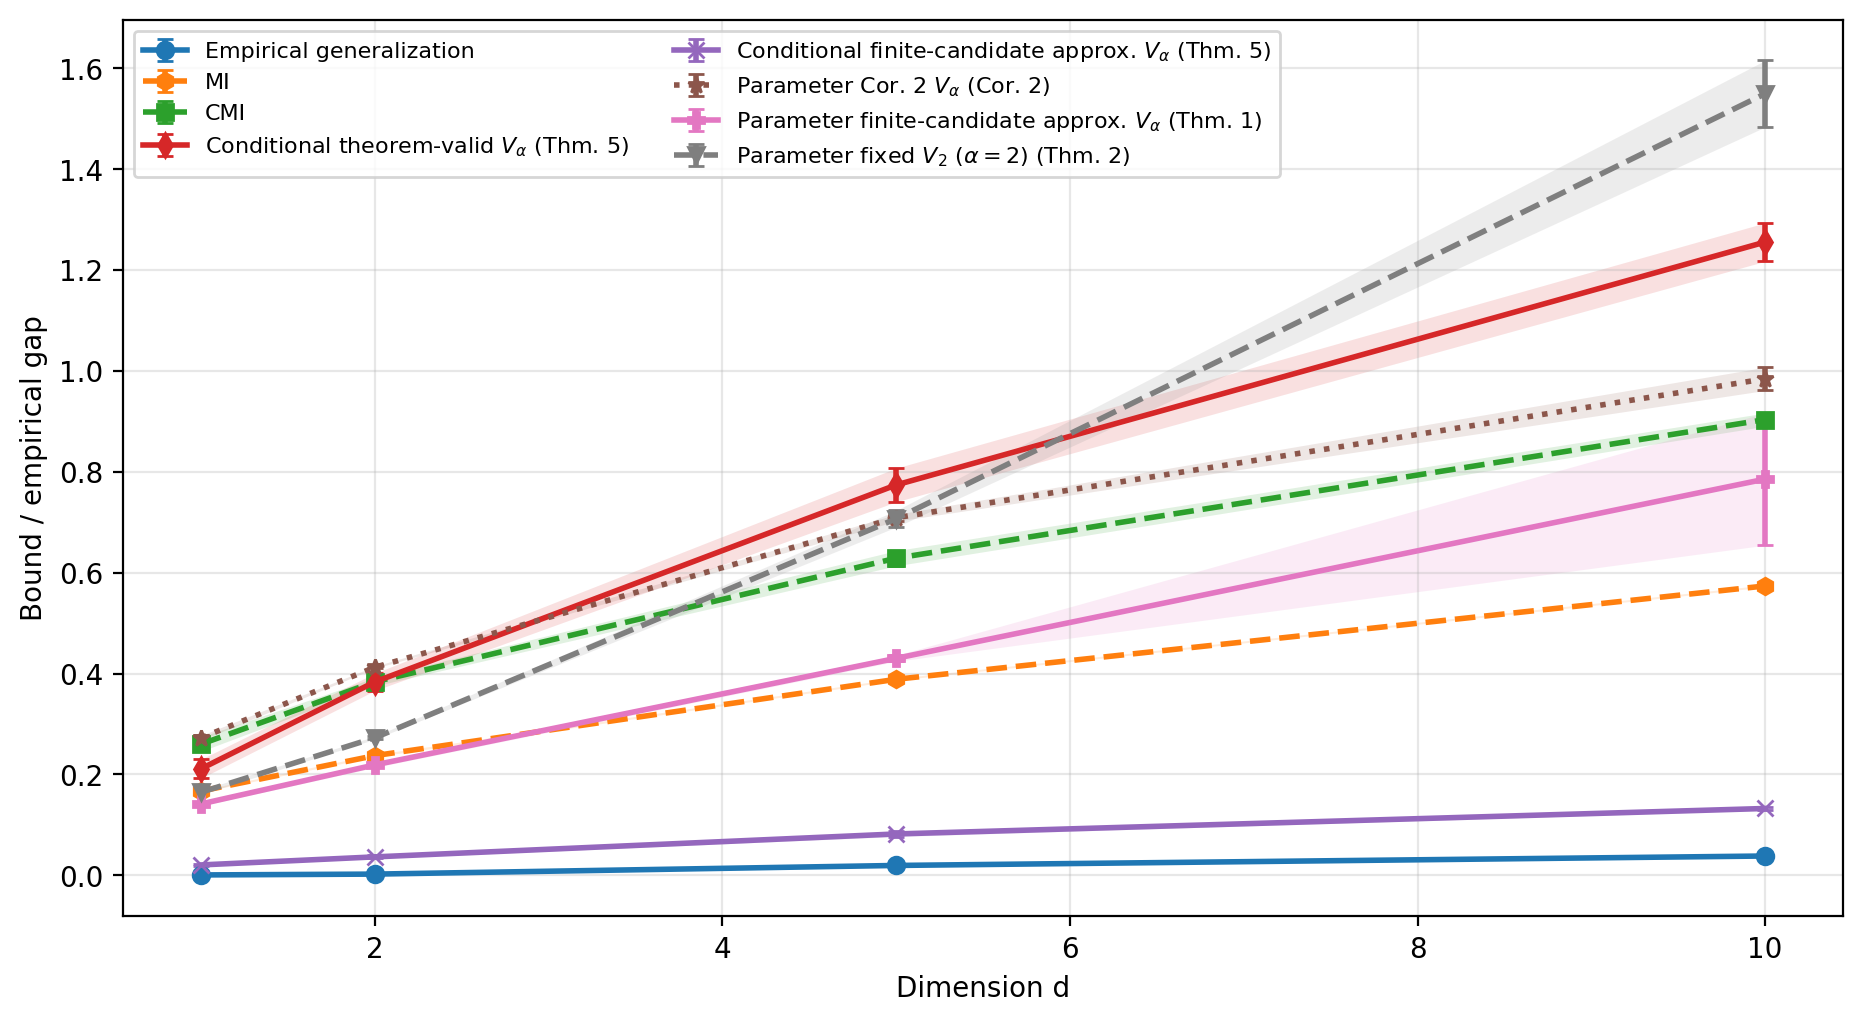

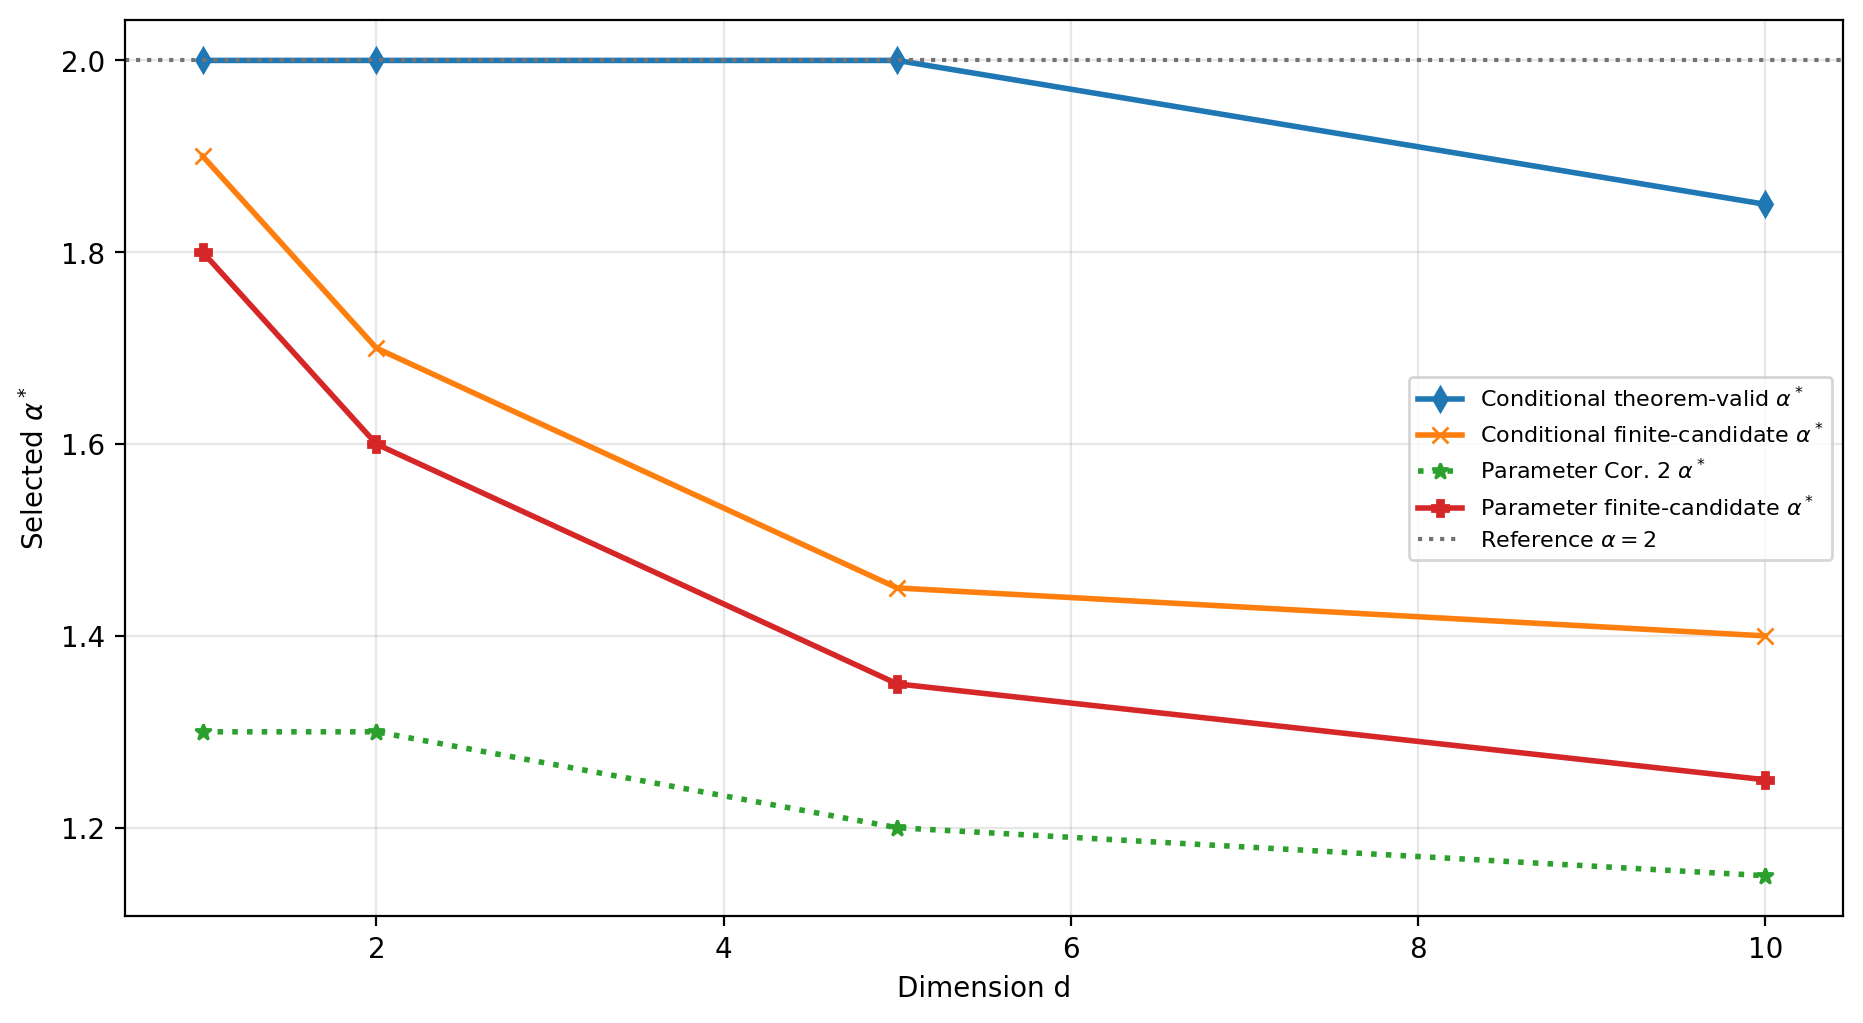

In [5]:
result_bundle = run_conditional_output_extended_first_figure(
    config,
    parameter_profile_selection_repeats=parameter_profile_selection_repeats,
    parameter_profile_evaluation_repeats=parameter_profile_evaluation_repeats,
    parameter_mi_repeats=parameter_mi_repeats,
    parameter_mi_weight_samples=parameter_mi_weight_samples,
    theorem1_proxy_selection_repeats=theorem1_proxy_selection_repeats,
    theorem1_proxy_evaluation_repeats=theorem1_proxy_evaluation_repeats,
    theorem1_proxy_num_means=theorem1_proxy_num_means,
    theorem1_proxy_num_marginal_samples=theorem1_proxy_num_marginal_samples,
    theorem1_proxy_num_prior_samples=theorem1_proxy_num_prior_samples,
    theorem1_candidate_batch_size=theorem1_candidate_batch_size,
)

display(result_bundle["conditional_results"])
display(result_bundle["conditional_alpha"].head(12))
display(result_bundle["theorem1_proxy_summary"])
display(result_bundle["sanity"])

print("\nSaved artifacts:")
print(json.dumps(portable_artifact_paths(result_bundle["diagnostics"]), indent=2))

display(Image(filename=result_bundle["diagnostics"]["figure_path"]))
display(Image(filename=result_bundle["diagnostics"]["alpha_figure_path"]))